# 04c - Harmonised nighttime lights (Chen et al.) on the 1 km grid

One consistent nighttime-lights series for every panel year, replacing DMSP (1992-2013) + VIIRS (2012-) and the imputation of pre-treatment VIIRS for cohorts before 2013.

* **Source:** Chen, Z., Yu, B., et al. (2021), *An extended time series (2000-2018) of global NPP-VIIRS-like nighttime light data from a cross-sensor calibration*, Earth System Science Data 13, 889-906, doi:10.5194/essd-13-889-2021. Data: Harvard Dataverse doi:10.7910/DVN/YGIVCD, **version 10** (released 2026-07-19, CC0), files `YYYY_Version2.zip` for 2000-2025, each a global NPP-VIIRS-like GeoTIFF (EPSG:4326, 0.0044916 deg, float32).
* **Aggregation (main, Earth Engine design):** reproduces what notebook 04's Earth Engine exports did for DMSP/VIIRS, `reduceRegions(reducer=mean, scale=1000)`. For an image stored in longitude/latitude, Earth Engine (i) takes the image pyramid level matching the requested scale, here the mean of 2x2 native pixels (native 0.0044916 deg = 500 m at Earth Engine's 111,319.49 m/deg, so 1,000 m is exactly level 1, anchored at the raster origin; the default 'mean' pyramiding policy is assumed for the asset), and (ii) averages those 1 km pixels over each cell polygon, weighting every pixel by the fraction of its area inside the cell. Both steps are done here exactly: a 2x2 block mean aligned to the raster origin, then fractional-overlap weights. The grid is rectilinear in longitude/latitude (regular columns of 0.0089832 deg; each row has its own height), so the overlaps factorise into a column and a row part and the cell means of a year are two sparse matrix products. Area is measured in degrees (the change of pixel area within one 1 km cell is negligible).
* **Comparison (native):** the same fractional-overlap mean computed directly on the native 500 m pixels, saved separately for reference.
* **Reading:** only the Colombia window of each global raster is read, directly from the zip (no extraction of the ~10 GB GeoTIFFs).
* **Output:** `data/intermediate/chen_ntl_1km.parquet` (Earth Engine design, main) and `chen_ntl_1km_native.parquet` (native, comparison), columns `cell_id`, `chen_ntl_2000` ... `chen_ntl_2025` (nW/cm2/sr, NPP-VIIRS-like radiance), plus a metadata JSON.

In [1]:
from pathlib import Path
import hashlib
import json
import time

import numpy as np
import pandas as pd
import pyogrio
import rasterio
from rasterio.windows import from_bounds
from scipy import sparse

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'notebooks').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DIR = PROJECT_ROOT / 'data' / 'raw' / 'chen_ntl'
ZIP_DIR = RAW_DIR / 'zips'
GRID_PATH = PROJECT_ROOT / 'data' / 'intermediate' / 'grid_geometry_1km_shp' / 'grid_geometry_1km.shp'
OUT_PATH = PROJECT_ROOT / 'data' / 'intermediate' / 'chen_ntl_1km.parquet'                # Earth Engine design (main)
OUT_NATIVE_PATH = PROJECT_ROOT / 'data' / 'intermediate' / 'chen_ntl_1km_native.parquet'  # native resolution (comparison)
GEE_SCALE_M = 1000                 # notebook 04's GEE_SCALE_NTL
GEE_METERS_PER_DEGREE = 111319.49079327357   # Earth Engine's nominal scale of 1 degree in EPSG:4326
META_PATH = PROJECT_ROOT / 'data' / 'intermediate' / 'chen_ntl_1km_metadata.json'
OLD_NTL_DIR = PROJECT_ROOT / 'data' / 'raw' / 'gee_covariates_core_1km'
YEARS = list(range(2000, 2026))
DATAVERSE_DOI = 'doi:10.7910/DVN/YGIVCD'
DATAVERSE_VERSION = '10.1'

## Verify the downloads against the Dataverse checksums

In [2]:
manifest = pd.read_csv(RAW_DIR / 'manifest.tsv', sep='\t', dtype=str)
manifest['md5'] = manifest['md5'].str.strip()
bad = []
for r in manifest.itertuples():
    p = ZIP_DIR / r.filename
    h = hashlib.md5()
    with open(p, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 24), b''):
            h.update(chunk)
    if h.hexdigest() != r.md5:
        bad.append(r.filename)
print(f'{len(manifest)} files checked; checksum mismatches: {bad or "none"}')
assert not bad

26 files checked; checksum mismatches: none


## Grid cell edges and the column / row overlap structure

In [3]:
t0 = time.time()
grid = pyogrio.read_dataframe(GRID_PATH)
b = grid.geometry.bounds
cells = pd.DataFrame({'cell_id': grid['cell_id'].astype(str).to_numpy(),
                      'minx': b['minx'].round(7), 'maxx': b['maxx'].round(7), 'miny': b['miny'].round(7), 'maxy': b['maxy'].round(7)})
del grid
cols = cells[['minx', 'maxx']].drop_duplicates().sort_values('minx').reset_index(drop=True)
rows = cells[['miny', 'maxy']].drop_duplicates().sort_values('maxy', ascending=False).reset_index(drop=True)
cells = cells.merge(cols.reset_index().rename(columns={'index': 'col'}), on=['minx', 'maxx']).merge(rows.reset_index().rename(columns={'index': 'row'}), on=['miny', 'maxy'])
assert cells['cell_id'].is_unique
assert not cells.duplicated(['row', 'col']).any(), 'two cells share a row and column: grid is not rectilinear'
print(f'{len(cells):,} cells in {len(rows):,} rows x {len(cols):,} columns  [{time.time() - t0:.0f}s]')
print('column widths (deg):', np.unique(np.round(cols['maxx'] - cols['minx'], 7))[:5], '| row heights (deg): min', round(float((rows['maxy'] - rows['miny']).min()), 7), 'max', round(float((rows['maxy'] - rows['miny']).max()), 7))
west, east = float(cols['minx'].min()), float(cols['maxx'].max())
south, north = float(rows['miny'].min()), float(rows['maxy'].max())

def overlap_matrix(lo, hi, edges):
    # sparse (n_intervals x n_pixels) matrix of overlap lengths between [lo, hi] and consecutive pixel edges;
    # edges may be increasing (longitude) or decreasing (latitude, north-up rasters)
    edges = np.asarray(edges, dtype=float)
    flip = edges[0] > edges[-1]
    e = edges[::-1] if flip else edges
    e0, e1 = e[:-1], e[1:]
    n_pix = len(e0)
    i_idx, j_idx, vals = [], [], []
    for k, (a, c) in enumerate(zip(lo, hi)):
        j0 = max(int(np.searchsorted(e1, a, side='right')) - 1, 0)
        j1 = min(int(np.searchsorted(e0, c, side='left')) + 1, n_pix)
        for j in range(j0, j1):
            ov = min(c, e1[j]) - max(a, e0[j])
            if ov > 0:
                i_idx.append(k); j_idx.append((n_pix - 1 - j) if flip else j); vals.append(ov)
    return sparse.csr_matrix((vals, (i_idx, j_idx)), shape=(len(lo), n_pix))

1,160,018 cells in 1,892 rows x 1,372 columns  [21s]
column widths (deg): [0.0089831 0.0089832] | row heights (deg): min 0.0087389 max 0.0089832


## Aggregate every year

In [4]:
def zip_path(year):
    name = f'{year}_Version2.zip'
    return f"zip://{(ZIP_DIR / name).as_posix()}!nppviirs_like_V2_{year}.tif"

with rasterio.open(zip_path(YEARS[0])) as src:
    native_res = abs(src.transform.a)
    FACTOR = int(round(GEE_SCALE_M / (native_res * GEE_METERS_PER_DEGREE)))
print(f'native pixel {native_res:.10f} deg = {native_res * GEE_METERS_PER_DEGREE:.2f} m; Earth Engine scale {GEE_SCALE_M} m -> pyramid factor {FACTOR}')
assert FACTOR >= 1 and abs(native_res * GEE_METERS_PER_DEGREE * FACTOR - GEE_SCALE_M) < 1.0, 'requested scale is not an exact pyramid level'

def aligned_window(src, f):
    # Colombia window (with margin) whose offsets and sizes are multiples of the pyramid factor, counted from the raster origin
    w = from_bounds(west - 0.02, south - 0.02, east + 0.02, north + 0.02, src.transform)
    c0 = int(np.floor(w.col_off / f) * f); r0 = int(np.floor(w.row_off / f) * f)
    c1 = int(np.ceil((w.col_off + w.width) / f) * f); r1 = int(np.ceil((w.row_off + w.height) / f) * f)
    return rasterio.windows.Window(c0, r0, c1 - c0, r1 - r0)

def cell_means(A, valid, T, cache, key):
    if key not in cache:
        x_edges = T.c + T.a * np.arange(A.shape[1] + 1)
        y_edges = T.f + T.e * np.arange(A.shape[0] + 1)
        cache[key] = (overlap_matrix(cols['minx'].to_numpy(), cols['maxx'].to_numpy(), x_edges),
                      overlap_matrix(rows['miny'].to_numpy(), rows['maxy'].to_numpy(), y_edges))
        print(f'  {key}: Wx {cache[key][0].shape}, Wy {cache[key][1].shape}')
    Wx, Wy = cache[key]
    S = (Wy @ sparse.csr_matrix(np.where(valid, A, 0.0)) @ Wx.T).toarray()
    N = (Wy @ sparse.csr_matrix(valid.astype(np.float64)) @ Wx.T).toarray()
    with np.errstate(invalid='ignore', divide='ignore'):
        M = np.where(N > 0, S / N, np.nan)
    return M[cells['row'].to_numpy(), cells['col'].to_numpy()]

cache = {}
gee_vals = np.full((len(cells), len(YEARS)), np.nan, dtype=np.float32)
nat_vals = np.full_like(gee_vals, np.nan)
summary = []
for k, year in enumerate(YEARS):
    t1 = time.time()
    with rasterio.open(zip_path(year)) as src:
        # every year has the same ~500 m pixel, but files store it with different precision (2000-2012: 0.0044915764;
        # 2013-2023: 0.004491576421; 2024-2025: 0.00449157642059761, origin -180.0, 83.658), so the check is relative 1e-6
        # and each year's overlap weights are built from its own exact transform (cache key below)
        assert src.crs.to_epsg() == 4326 and abs(abs(src.transform.a) / native_res - 1) < 1e-6 and abs(abs(src.transform.e) / native_res - 1) < 1e-6
        win = aligned_window(src, FACTOR)
        A = src.read(1, window=win).astype(np.float64)
        T = src.window_transform(win)
        nodata = src.nodata
    # 2013+ files flag missing pixels with the float32 minimum (-3.4e38); radiance is never negative
    valid = np.isfinite(A) & (A > -1e30) & ((A != nodata) if nodata is not None else True)
    # native: fractional-overlap mean of the 500 m pixels
    origin = (round(T.c, 9), round(T.f, 9), repr(T.a), repr(T.e))
    nat_vals[:, k] = cell_means(A, valid, T, cache, ('native', A.shape, origin))
    # Earth Engine design: pyramid level (mean of FACTOR x FACTOR valid native pixels), then fractional-overlap mean
    h, w = A.shape[0] // FACTOR, A.shape[1] // FACTOR
    sums = np.where(valid, A, 0.0).reshape(h, FACTOR, w, FACTOR).sum(axis=(1, 3))
    cnt = valid.reshape(h, FACTOR, w, FACTOR).sum(axis=(1, 3))
    with np.errstate(invalid='ignore', divide='ignore'):
        A2 = np.where(cnt > 0, sums / cnt, 0.0)
    T2 = T * rasterio.Affine.scale(FACTOR)
    gee_vals[:, k] = cell_means(A2, cnt > 0, T2, cache, ('gee', A2.shape, origin))
    g, n = gee_vals[:, k], nat_vals[:, k]
    summary.append({'year': year, 'raster_origin': origin, 'nodata_pixels': int((~valid).sum()), 'mean_gee_design': float(np.nanmean(g)), 'mean_native': float(np.nanmean(n)),
                    'corr_gee_vs_native': float(np.corrcoef(g, n)[0, 1]), 'cells_lit': int((g > 0).sum()), 'max': float(np.nanmax(g)),
                    'seconds': round(time.time() - t1)})
    print(summary[-1])
summary = pd.DataFrame(summary)
for vals, path in [(gee_vals, OUT_PATH), (nat_vals, OUT_NATIVE_PATH)]:
    df = pd.DataFrame(vals, columns=[f'chen_ntl_{y}' for y in YEARS])
    df.insert(0, 'cell_id', cells['cell_id'].to_numpy())
    df.to_parquet(path, index=False)
    print('Saved:', path, df.shape)
out = pd.read_parquet(OUT_PATH)
META_PATH.write_text(json.dumps({
    'source': 'Chen et al. (2021) ESSD 13:889-906, NPP-VIIRS-like nighttime lights', 'dataverse': DATAVERSE_DOI, 'dataverse_version': DATAVERSE_VERSION,
    'files': 'YYYY_Version2.zip', 'years': YEARS, 'grid': str(GRID_PATH.name),
    'method_main': f'Earth Engine design: pyramid level {FACTOR}x{FACTOR} mean (scale {GEE_SCALE_M} m) then fractional-overlap mean over each 1 km cell',
    'method_comparison': 'fractional-overlap mean of native pixels over each 1 km cell', 'outputs': [OUT_PATH.name, OUT_NATIVE_PATH.name],
    'units': 'NPP-VIIRS-like radiance (nW/cm2/sr)', 'created': time.strftime('%Y-%m-%d %H:%M'),
}, indent=2))
display(summary)

native pixel 0.0044915764 deg = 500.00 m; Earth Engine scale 1000 m -> pyramid factor 2


  ('native', (3936, 3346), (-81.876947021, 13.423357595, '0.0044915764', '-0.0044915764')): Wx (1372, 3346), Wy (1892, 3936)


  ('gee', (1968, 1673), (-81.876947021, 13.423357595, '0.0044915764', '-0.0044915764')): Wx (1372, 1673), Wy (1892, 1968)


{'year': 2000, 'raster_origin': (-81.876947021, 13.423357595, '0.0044915764', '-0.0044915764'), 'nodata_pixels': 0, 'mean_gee_design': 0.07271162420511246, 'mean_native': 0.07275599986314774, 'corr_gee_vs_native': 0.9957543003494094, 'cells_lit': 35942, 'max': 59.374637603759766, 'seconds': 70}


{'year': 2001, 'raster_origin': (-81.876947021, 13.423357595, '0.0044915764', '-0.0044915764'), 'nodata_pixels': 0, 'mean_gee_design': 0.08406265825033188, 'mean_native': 0.08410043269395828, 'corr_gee_vs_native': 0.99495066820529, 'cells_lit': 72849, 'max': 61.79840087890625, 'seconds': 68}


...

{'year': 2024, 'raster_origin': (-81.877021516, 13.418622053, '0.00449157642059761', '-0.00449157642059761'), 'nodata_pixels': 0, 'mean_gee_design': 0.18554753065109253, 'mean_native': 0.1856060028076172, 'corr_gee_vs_native': 0.9899673206421532, 'cells_lit': 71326, 'max': 230.56463623046875, 'seconds': 44}


{'year': 2025, 'raster_origin': (-81.877021516, 13.418622053, '0.00449157642059761', '-0.00449157642059761'), 'nodata_pixels': 0, 'mean_gee_design': 0.17520345747470856, 'mean_native': 0.1752629280090332, 'corr_gee_vs_native': 0.9891642901605702, 'cells_lit': 67103, 'max': 266.3234558105469, 'seconds': 62}


Saved: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2\data\intermediate\chen_ntl_1km.parquet (1160018, 27)


Saved: C:\Users\cpedr\OneDrive - Hertie School\PhD\Paper 2\paper2\data\intermediate\chen_ntl_1km_native.parquet (1160018, 27)


,year,raster_origin,nodata_pixels,mean_gee_design,mean_native,corr_gee_vs_native,cells_lit,max,seconds
0,2000,"(-81.876947021, 13.423357595, 0.0044915764, -0...",0,0.072712,0.072756,0.995754,35942,59.374638,70
1,2001,"(-81.876947021, 13.423357595, 0.0044915764, -0...",0,0.084063,0.084100,0.994951,72849,61.798401,68
2,2002,"(-81.876947021, 13.423357595, 0.0044915764, -0...",0,0.085568,0.085621,0.994784,70973,62.799866,79
3,2003,"(-81.876947021, 13.423357595, 0.0044915764, -0...",0,0.080947,0.080987,0.994696,65198,61.191498,80
4,2004,"(-81.876947021, 13.423357595, 0.0044915764, -0...",0,0.082297,0.082314,0.994676,80946,65.085793,72
5,2005,"(-81.876947021, 13.423357595, 0.0044915764, -0...",0,0.079414,0.079436,0.995065,67630,63.266880,70
6,2006,"(-81.876947021, 13.423357595, 0.0044915764, -0...",0,0.083098,0.083124,0.994472,63590,60.586021,81
7,2007,"(-81.876947021, 13.423357595, 0.0044915764, -0...",0,0.088465,0.088503,0.994315,68250,63.920914,72
8,2008,"(-81.876947021, 13.423357595, 0.0044915764, -0...",0,0.083279,0.083309,0.994517,66774,65.216629,71
9,2009,"(-81.876947021, 13.423357595, 0.0044915764, -0...",0,0.085722,0.085749,0.993957,68680,65.376663,81


## Checks: consistency over time and against the old DMSP / VIIRS exports

,year,compared_with,cells,pearson,spearman
0,2001,DMSP,1160018,0.707,0.709
1,2002,DMSP,1160018,0.697,0.711
2,2003,DMSP,1160018,0.736,0.700
3,2004,DMSP,1160018,0.734,0.708
4,2005,DMSP,1160018,0.753,0.683
5,2006,DMSP,1160018,0.730,0.671
6,2007,DMSP,1160018,0.719,0.693
7,2008,DMSP,1160018,0.671,0.685
8,2009,DMSP,1160018,0.719,0.766
9,2010,DMSP,1160018,0.662,0.698


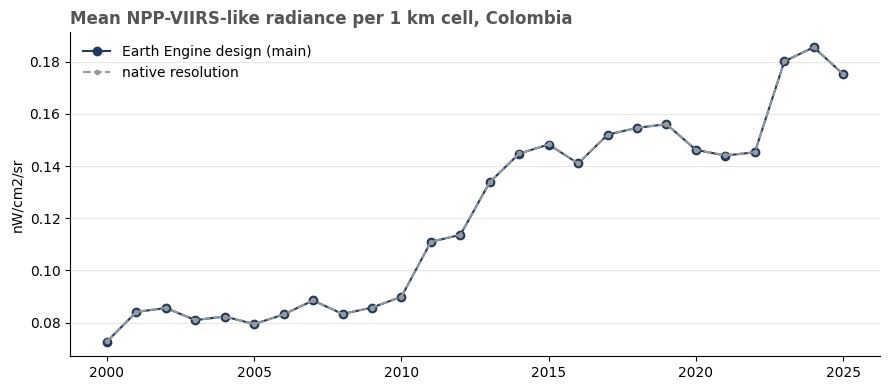

In [5]:
import matplotlib.pyplot as plt
checks = []
old = None
files = sorted(OLD_NTL_DIR.glob('core_covariates_1km_ntl*.csv')) if OLD_NTL_DIR.exists() else []
if files:
    old = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    old['cell_id'] = old['cell_id'].astype(str)
    m = out.merge(old, on='cell_id', how='inner')
    for y in YEARS:
        for col in [f'viirs_avg_rad_{y}', f'dmsp_stable_lights_{y}']:
            if col in m.columns:
                a, b2 = m[f'chen_ntl_{y}'], m[col]
                ok = a.notna() & b2.notna()
                checks.append({'year': y, 'compared_with': col.split('_')[0].upper(), 'cells': int(ok.sum()),
                               'pearson': float(np.corrcoef(a[ok], b2[ok])[0, 1]), 'spearman': float(a[ok].rank().corr(b2[ok].rank()))})
    checks = pd.DataFrame(checks)
    display(checks.round(3))
else:
    print('Old nightlight exports not found in', OLD_NTL_DIR)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(summary['year'], summary['mean_gee_design'], marker='o', color='#1f3a5f', label='Earth Engine design (main)')
ax.plot(summary['year'], summary['mean_native'], marker='.', linestyle='--', color='#999999', label='native resolution')
ax.legend(frameon=False)
ax.set_title('Mean NPP-VIIRS-like radiance per 1 km cell, Colombia', loc='left', color='#555555', fontsize=12, weight='bold')
ax.set_ylabel('nW/cm2/sr'); ax.grid(True, axis='y', color='#e7e7e7'); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
fig.tight_layout(); fig.savefig(PROJECT_ROOT / 'outputs' / 'figures' / '04c_chen_ntl_mean_by_year_1km.png', dpi=200, bbox_inches='tight'); plt.show()